# Analysis 4: Statistical Significance Testing & Hypothesis Evaluation
**Jira User Story:** `CDS-76` — Advanced Analysis (Acceptance Criterion 4)  
**Significance Level:** $\alpha = 0.05$, using nonparametric tests (due to strong right-skew in `selling_price`), Holm–Bonferroni multiple-comparison adjustments, effect sizes, bootstrap CIs, and HC3 robust Wald F-tests.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

SCRIPTS_DIR = Path("scripts").resolve()
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from common import load_dataset, OUTPUT_FIG_DIR
from statistical_testing import run_statistical_testing

df = load_dataset()
res4 = run_statistical_testing(df)

print("=== A. Mann-Whitney U Tests: Dealer vs Individual (Holm-corrected) ===")
display(pd.DataFrame(res4["mann_whitney_dealer_vs_individual"]["all_seller_metric_tests"]))

kw = res4["kruskal_wallis_body_types"]
print(f"\n=== B. Kruskal-Wallis H Test (Major Body Types, n={kw['n_total']:,}, k={kw['k_groups']}) ===")
print(f"H = {kw['h_statistic']:,.2f}, df = {kw['df']}, p = {kw['p_value']:.4e}, epsilon^2 = {kw['epsilon_squared']:.4f}")
print("\n=== C. Post-Hoc Pairwise Mann-Whitney U (Holm-Bonferroni corrected) ===")
display(pd.DataFrame(kw["posthoc_holm"]))

=== A. Mann-Whitney U Tests: Dealer vs Individual (Holm-corrected) ===


,variable,label,dealer_n,individual_n,dealer_median,individual_median,median_diff_dealer_minus_indiv,median_diff_ci95,u_statistic,p_value_raw,rank_biserial_r,p_value_holm,significant_at_0_05
0,selling_price,Listing Price (INR),9446,5610,590000.0,510000.0,80000.0,"[65000.0, 98500.0]",31215900.5,7.578479e-75,0.178135,2.273544e-74,True
1,vehicle_age,Vehicle Age (Years),9446,5610,6.0,5.0,1.0,"[1.0, 1.0]",28624898.5,9.999734e-17,0.080347,1.999947e-16,True
2,km_driven,Kilometers Driven,9446,5610,50000.0,50000.0,0.0,"[0.0, 1000.0]",25400045.5,2.130322e-05,-0.041364,2.130322e-05,True



=== B. Kruskal-Wallis H Test (Major Body Types, n=9,817, k=4) ===
H = 3,210.32, df = 3, p = 0.0000e+00, epsilon^2 = 0.3268

=== C. Post-Hoc Pairwise Mann-Whitney U (Holm-Bonferroni corrected) ===


,group_1,group_2,n_1,n_2,median_1,median_2,median_diff_g1_minus_g2,median_diff_ci95,u_statistic,p_value_raw,rank_biserial_r,p_value_holm,significant_at_0_05
0,Hatchback,Sedan,3601,2839,435000.0,625000.0,-190000.0,"[-210000.0, -163425.0000000004]",2738515.0,3.232794e-225,-0.464257,1.616397e-224,True
1,Hatchback,SUV,3601,2819,435000.0,880000.0,-445000.0,"[-466000.0, -425000.0]",1236549.5,0.000000e+00,-0.756374,0.000000e+00,True
2,Hatchback,MUV,3601,558,435000.0,1077500.0,-642500.0,"[-736312.5, -559237.5000000001]",160204.5,1.135493e-224,-0.840542,4.541971e-224,True
3,Sedan,SUV,2839,2819,625000.0,880000.0,-255000.0,"[-285000.0, -235000.0]",2791423.0,2.194563e-86,-0.302418,6.583690e-86,True
4,Sedan,MUV,2839,558,625000.0,1077500.0,-452500.0,"[-550000.0, -370000.0]",449266.0,6.271866e-59,-0.432803,1.254373e-58,True
5,SUV,MUV,2819,558,880000.0,1077500.0,-197500.0,"[-299525.0, -110000.0]",637939.5,1.661247e-12,-0.188889,1.661247e-12,True


### Nonparametric Group Comparison Interpretation
- **Dealer vs. Individual (`Mann–Whitney U`):** We reject $H_0$ ($U = 31,215,900.5, p = 7.58 \times 10^{-75}, p_{\text{Holm}} = 2.27 \times 10^{-74}$). Median difference is `+₹80,000` (95% bootstrap CI: `[₹65,000, ₹98,500]`), with a **small-to-moderate effect size** ($r_{\text{rb}} = +0.178$). Note that mileage (`km_driven`) also shows $p = 2.13 \times 10^{-5}$ due to large `N` even though both groups have an identical median (`50,000 km`, $|r_{\text{rb}}| = 0.041$) — a textbook reminder that statistical significance does not automatically equal practical importance.
- **Body Types (`Kruskal–Wallis H`):** We reject $H_0$ ($H = 3,210.32, df = 3, p < 10^{-300}$) with a **large effect size** ($\varepsilon^2 = 0.327$). All 6 Holm-adjusted pairwise body-type differences are significant at $p_{\text{Holm}} < 0.001$, led by `Hatchback vs. MUV` ($r_{\text{rb}} = -0.841$) and `Hatchback vs. SUV` ($r_{\text{rb}} = -0.756$).

=== D. HC3 Joint Wald F-Tests (n=9,817 Major Body Types, R²=0.9183) ===


,terms,f_stat,df_num,df_denom,p_value,significant_at_0_05
seller_type_joint,"[C(seller_type, Treatment(reference='Individua...",64.840586,2,9740,0.0,True
transmission_main_hatchback,"[C(transmission_type, Treatment(reference='Man...",187.985943,1,9740,0.0,True
body_type_main_joint,"[C(real_body_type, Treatment(reference='Hatchb...",1661.243233,3,9740,0.0,True
transmission_x_body_interaction_joint,"[C(transmission_type, Treatment(reference='Man...",2.861242,3,9740,0.035423,True



Key Individual HC3 Coefficients:


,coef,hc3_se,t_stat,p_value,pct_effect,pct_ci95_low,pct_ci95_high
"C(seller_type, Treatment(reference='Individual'))[T.Dealer]",0.052851,0.004705,11.233113,2.804225e-29,5.427291,4.459557,6.403991
"C(seller_type, Treatment(reference='Individual'))[T.Trustmark Dealer]",-0.002003,0.019563,-0.102394,9.184436e-01,-0.200110,-3.954214,3.700729
"C(transmission_type, Treatment(reference='Manual'))[T.Automatic]",0.129745,0.009463,13.710797,8.749196e-43,13.853792,11.761598,15.985153
"C(real_body_type, Treatment(reference='Hatchback'))[T.MUV]",0.862339,0.016784,51.379650,0.000000e+00,136.869458,129.204311,144.790946
"C(real_body_type, Treatment(reference='Hatchback'))[T.SUV]",1.748837,0.032675,53.522771,0.000000e+00,474.791364,439.135011,512.805893
"C(real_body_type, Treatment(reference='Hatchback'))[T.Sedan]",1.276933,0.021714,58.806604,0.000000e+00,258.562590,243.622737,274.151990
"C(transmission_type, Treatment(reference='Manual'))[T.Automatic]:C(real_body_type, Treatment(reference='Hatchback'))[T.MUV]",-0.037896,0.020834,-1.818975,6.891518e-02,-3.718703,-7.571011,0.294164
"C(transmission_type, Treatment(reference='Manual'))[T.Automatic]:C(real_body_type, Treatment(reference='Hatchback'))[T.SUV]",0.008687,0.015732,0.552198,5.808126e-01,0.872492,-2.190328,4.031222
"C(transmission_type, Treatment(reference='Manual'))[T.Automatic]:C(real_body_type, Treatment(reference='Hatchback'))[T.Sedan]",0.025528,0.014437,1.768269,7.701600e-02,2.585696,-0.276366,5.529900


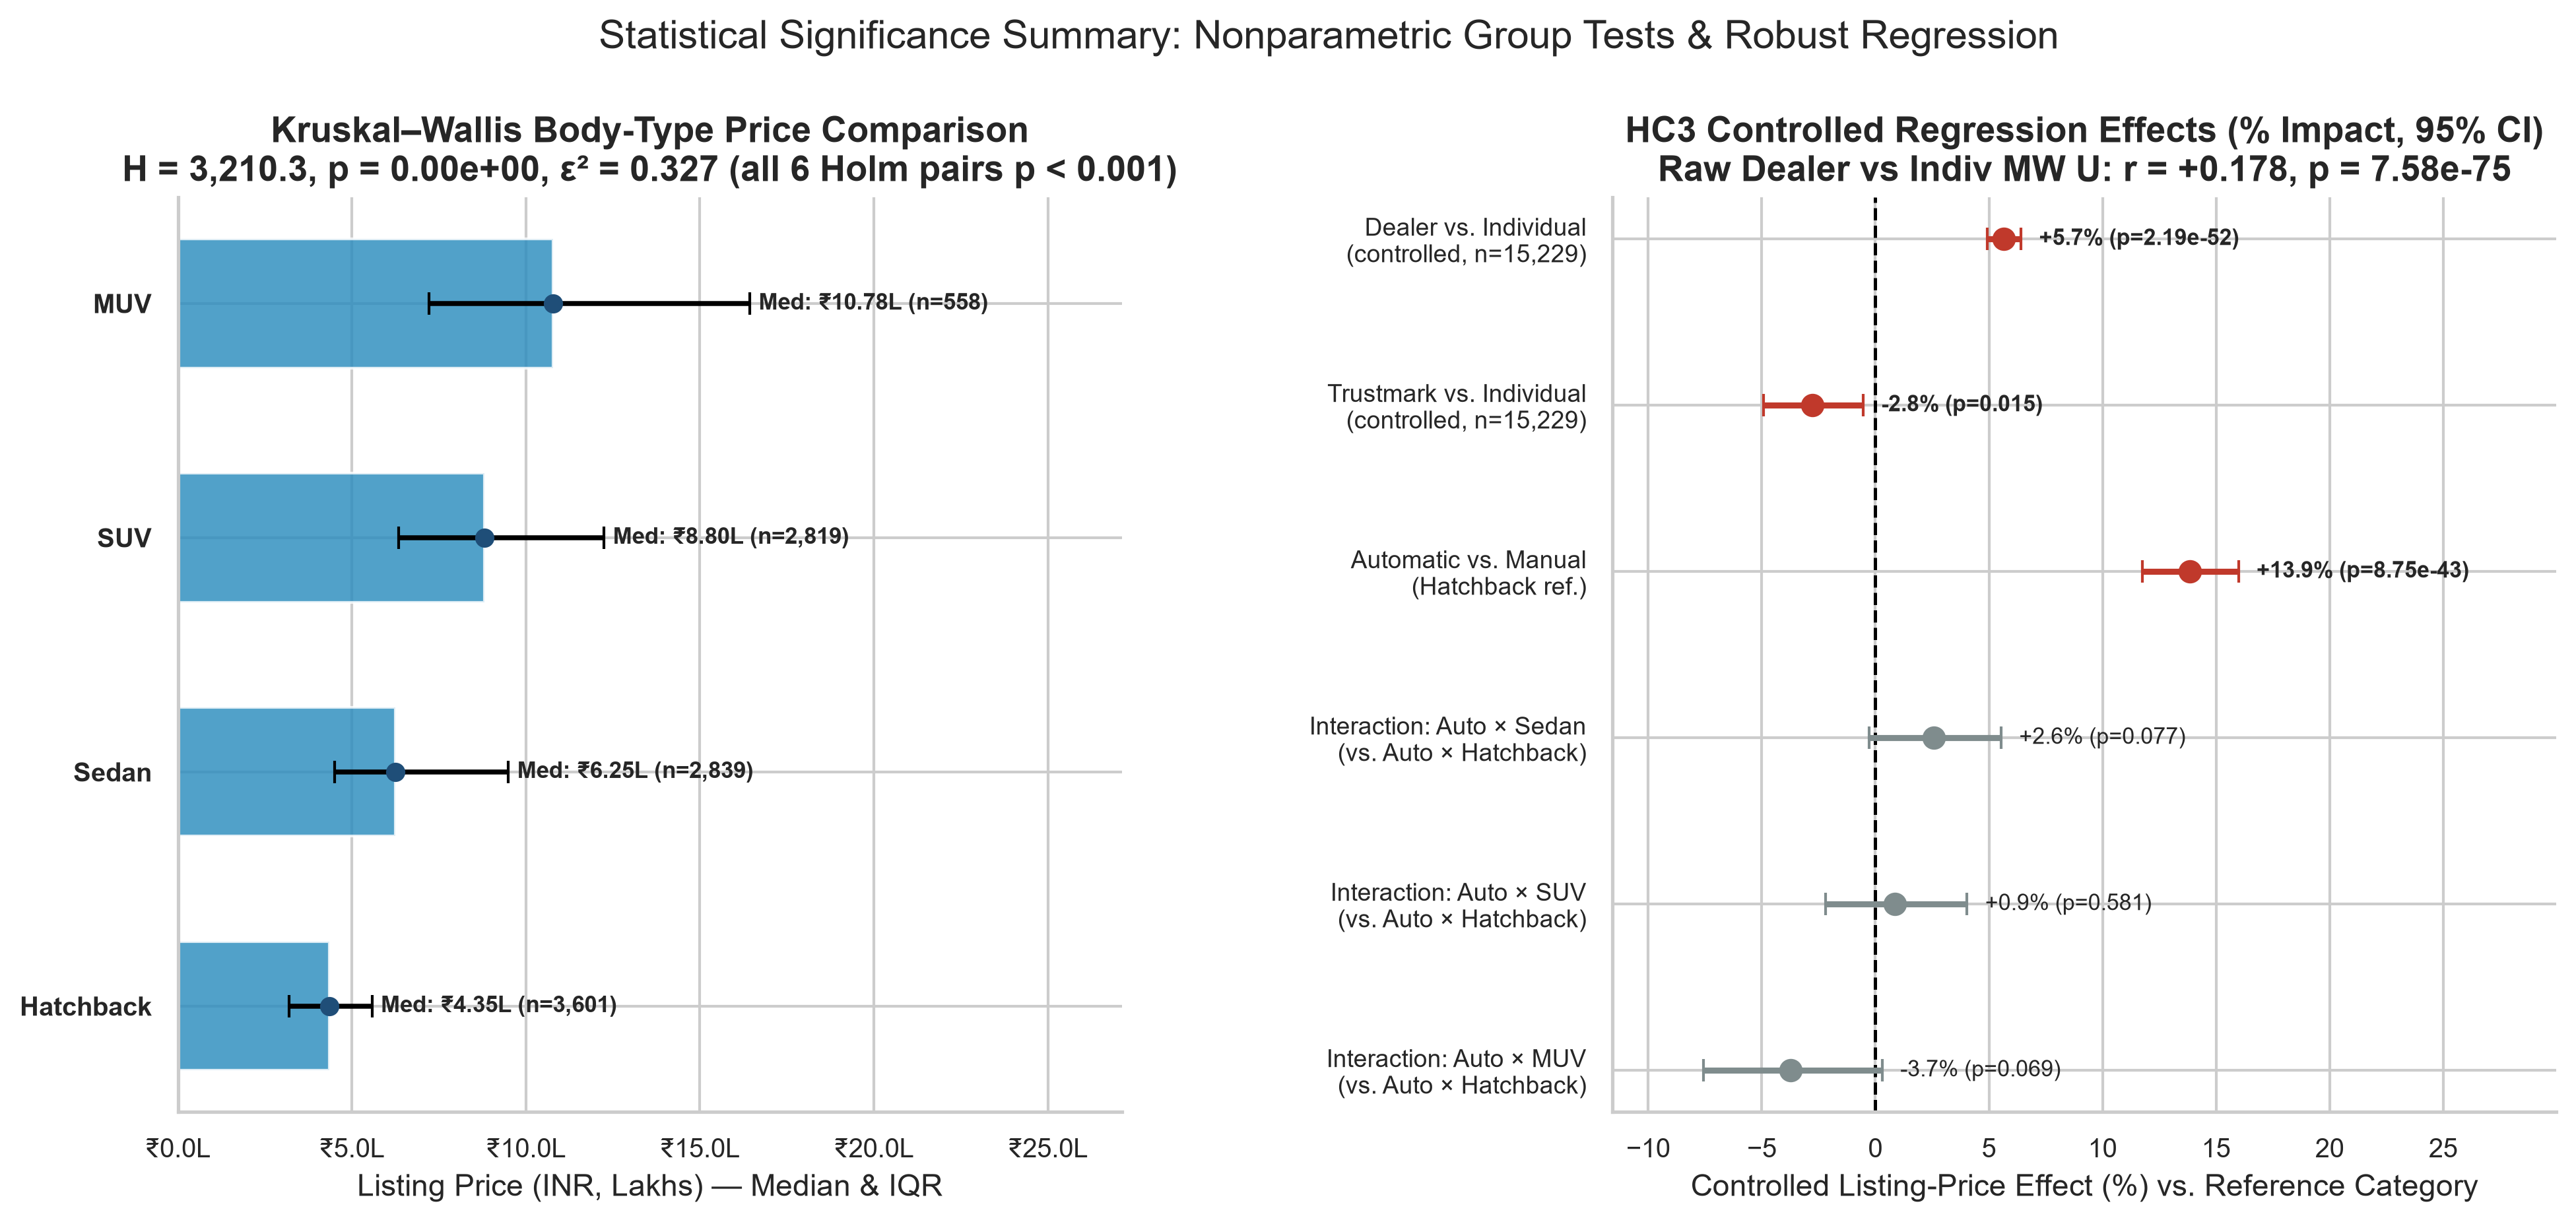

In [2]:
reg_h = res4["regression_hypothesis_tests"]
print("=== D. HC3 Joint Wald F-Tests (n=9,817 Major Body Types, R²={:.4f}) ===".format(reg_h["major_body_model_r2"]))
display(pd.DataFrame(reg_h["joint_tests"]).T)
print("\nKey Individual HC3 Coefficients:")
display(pd.DataFrame(reg_h["individual_coefficients"]).T[["coef", "hc3_se", "t_stat", "p_value", "pct_effect", "pct_ci95_low", "pct_ci95_high"]])

display(Image(filename=str(OUTPUT_FIG_DIR / "statistical_test_summary.png"), width=820))

### Regression Hypothesis Testing Conclusion
- **Seller-Type Joint Test:** $F(2, 9740) = 64.84, p = 1.06 \times 10^{-28}$ (driven by Dealer `+5.43%` in major body types / `+5.66%` across all 15,229 records).
- **Transmission & Body-Type Main Effects:** Both highly significant ($F = 187.99, p = 2.16 \times 10^{-42}$ for Automatic in Hatchback; $F = 1661.24, p < 10^{-300}$ across body types).
- **Transmission × Body-Type Interaction:** Jointly significant ($F(3, 9740) = 2.86, p = 0.0354$), confirming modest variation in the Automatic premium across segments (`+9.6%` MUV to `+16.8%` Sedan), though much smaller than unadjusted medians suggest.